In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('ice_cream_sales_data.csv')
df['Counter'] = np.arange(1, len(df) + 1)
df

,Temperature,Humidity,Is_Weekend,Rainfall_Intensity,Sales_Revenue,Counter
0,34.540572,60.774939,0.0,0.919143,493.446603,1
1,22.176360,40.167044,1.0,2.515130,676.402807,2
2,15.301795,60.246362,1.0,9.031185,581.827992,3
3,24.557008,75.506242,0.0,0.961272,723.631829,4
4,35.806468,72.713934,0.0,1.367272,551.761034,5
...,...,...,...,...,...,...
20395,39.162778,59.883959,1.0,0.891168,668.557877,20396
20396,26.636939,74.982602,0.0,1.397169,462.274044,20397
20397,29.260794,50.375258,0.0,4.329173,NaN,20398
20398,31.848399,80.183649,1.0,1.066689,700.605913,20399


In [2]:

df['Temperature'] = round(df['Temperature'], 0)
df['Humidity'] = round(df['Humidity'], 0)
df['Rainfall_Intensity'] = round(df['Rainfall_Intensity'], 1)
df['Sales_Revenue'] = round(df['Sales_Revenue'], 2)
df.isnull().sum()

Temperature           404
Humidity              305
Is_Weekend             16
Rainfall_Intensity    208
Sales_Revenue         510
Counter                 0
dtype: int64

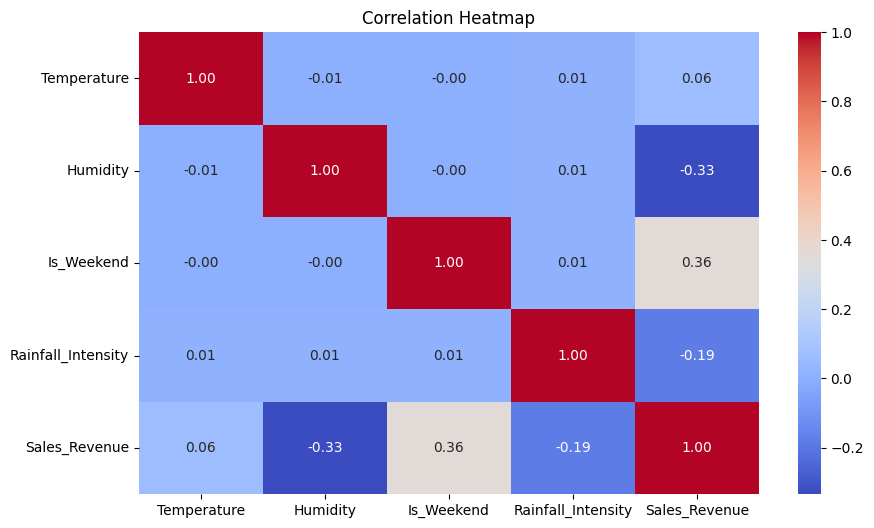

In [3]:
corr = df.drop(columns=["Counter"]).select_dtypes(include=["number"]).corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [4]:
avg_temperature = round(df['Temperature'].mean(), 2)
avg_humidity = round(df['Humidity'].mean(), 2)
avg_rainfall = round(df['Rainfall_Intensity'].mean(), 2)
print(f"Average Temperature: {avg_temperature}","\n",f"Average Humidity: {avg_humidity}","\n",f"Average Rainfall: {avg_rainfall}")

Average Temperature: 27.56 
 Average Humidity: 60.18 
 Average Rainfall: 2.02


In [5]:
med_temperature = round(df['Temperature'].median(), 2)
med_humidity = round(df['Humidity'].median(), 2)
med_rainfall = round(df['Rainfall_Intensity'].median(), 2)
print(f"Median Temperature: {med_temperature}","\n",f"Median Humidity: {med_humidity}","\n",f"Median Rainfall: {med_rainfall}")

Median Temperature: 28.0 
 Median Humidity: 60.0 
 Median Rainfall: 1.4


In [6]:
min_temperature = round(df['Temperature'].min(), 2)
max_temperature = round(df['Temperature'].max(), 2)
min_humidity = round(df['Humidity'].min(), 2)
max_humidity = round(df['Humidity'].max(), 2)
min_rainfall = round(df['Rainfall_Intensity'].min(), 2)
max_rainfall = round(df['Rainfall_Intensity'].max(), 2)
print(f"Minimum Temperature: {min_temperature}","\n",
      f"Maximum Temperature: {max_temperature}","\n",
      f"Minimum Humidity: {min_humidity}","\n",
      f"Maximum Humidity: {max_humidity}","\n",
      f"Minimum Rainfall: {min_rainfall}","\n",
      f"Maximum Rainfall: {max_rainfall}")

Minimum Temperature: -10.0 
 Maximum Temperature: 60.0 
 Minimum Humidity: 30.0 
 Maximum Humidity: 90.0 
 Minimum Rainfall: 0.0 
 Maximum Rainfall: 21.0


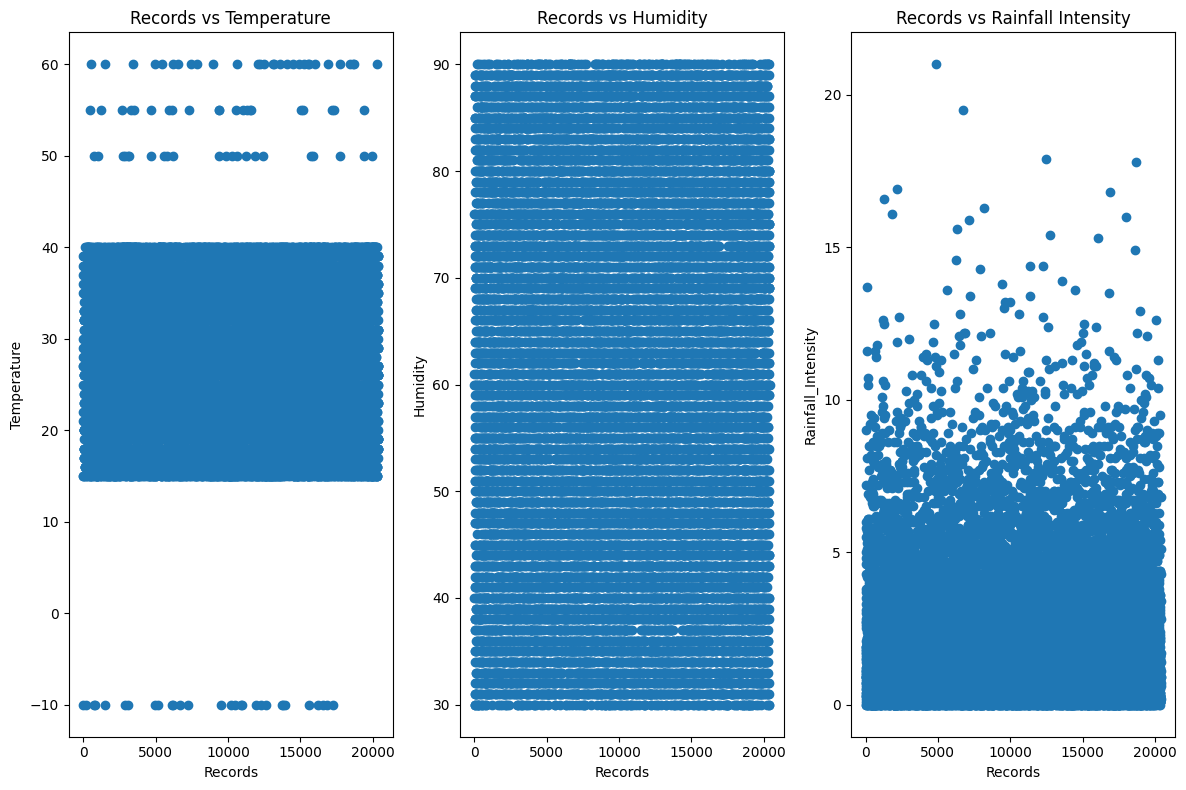

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 8))
plots = [
    ('Temperature', 'Records vs Temperature'),
    ('Humidity', 'Records vs Humidity'),
    ('Rainfall_Intensity', 'Records vs Rainfall Intensity')
]

for ax, (column, title) in zip(axes.flat, plots):
    ax.scatter(df['Counter'], df[column])
    ax.set_title(title)
    ax.set_xlabel('Records')
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

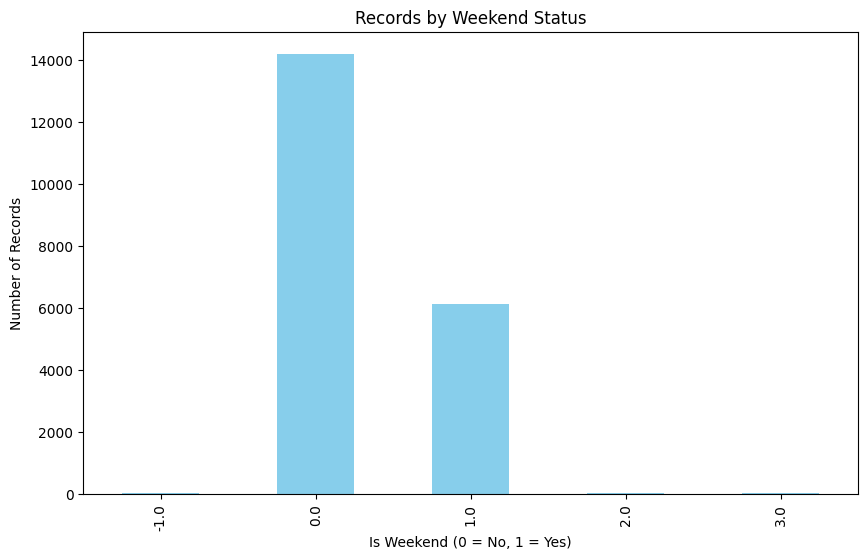

In [8]:
df['Humidity'] = df['Humidity'].fillna(med_humidity)
df['Is_Weekend'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(10, 6),
    color='skyblue'
)

plt.xlabel('Is Weekend (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')
plt.title('Records by Weekend Status')
plt.show()

In [9]:
df_inco = df[~df['Is_Weekend'].isin([0, 1])]

cnt = df_inco.shape[0]
cnt

61

In [10]:
df = df.dropna(subset=['Is_Weekend'])
df = df.loc[df['Is_Weekend'].isin([0, 1])]
df

,Temperature,Humidity,Is_Weekend,Rainfall_Intensity,Sales_Revenue,Counter
0,35.0,61.0,0.0,0.9,493.45,1
1,22.0,40.0,1.0,2.5,676.40,2
2,15.0,60.0,1.0,9.0,581.83,3
3,25.0,76.0,0.0,1.0,723.63,4
4,36.0,73.0,0.0,1.4,551.76,5
...,...,...,...,...,...,...
20395,39.0,60.0,1.0,0.9,668.56,20396
20396,27.0,75.0,0.0,1.4,462.27,20397
20397,29.0,50.0,0.0,4.3,NaN,20398
20398,32.0,80.0,1.0,1.1,700.61,20399


In [11]:
df['Is_Weekend'] = df['Is_Weekend'].astype(int)

df_extreme_temp = df[(df['Temperature'] < 0)]
counting = df_extreme_temp.shape[0]
print(f"Number of records with temperature less than 0: {counting}")

Number of records with temperature less than 0: 29


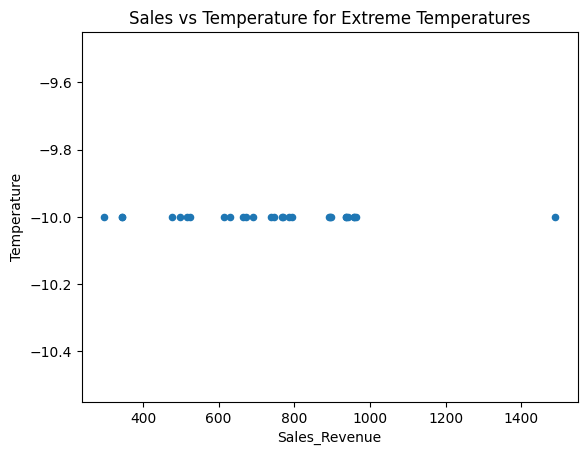

In [12]:
plot = df_extreme_temp.plot(
    x='Sales_Revenue',
    y='Temperature',
    kind='scatter',
    title='Sales vs Temperature for Extreme Temperatures'
)

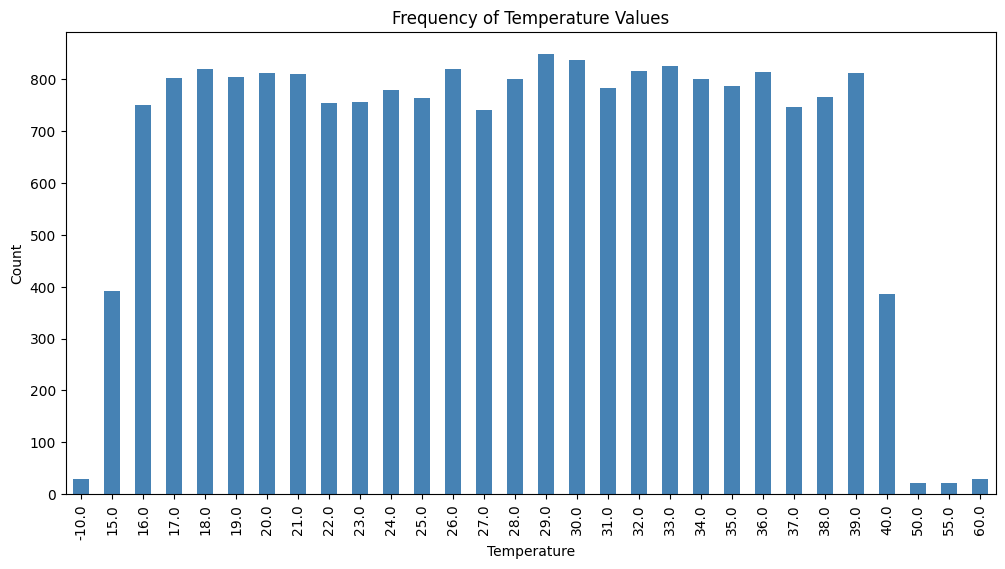

In [13]:
df['Temperature'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(12, 6),
    color='steelblue'
)
plt.title('Frequency of Temperature Values')
plt.xlabel('Temperature')
plt.ylabel('Count')
plt.show()

In [14]:
df_extreme_temp = df[(df['Temperature'] > 40)]
counting = df_extreme_temp.shape[0]
print(f"Number of records with temperature greater than 40: {counting}")

Number of records with temperature greater than 40: 73


In [15]:
df = df[(df['Temperature'] <= 40) & (df['Temperature'] >= 0)]
df['Temperature'] = df['Temperature'].fillna(med_temperature)


avg_sales = round(df['Sales_Revenue'].mean(), 2)
min_sales = round(df['Sales_Revenue'].min(), 2)
max_sales = round(df['Sales_Revenue'].max(), 2)
median_sales = round(df['Sales_Revenue'].median(), 2)
print(f"Average Sales Revenue: {avg_sales}","\n",
      f"Minimum Sales Revenue: {min_sales}","\n",
      f"Maximum Sales Revenue: {max_sales}","\n",
      f"Median Sales Revenue: {median_sales}")

Average Sales Revenue: 639.42 
 Minimum Sales Revenue: 0.0 
 Maximum Sales Revenue: 4761.84 
 Median Sales Revenue: 614.67


C:\Users\panos\AppData\Local\Temp\ipykernel_35544\3365908553.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Temperature'] = df['Temperature'].fillna(med_temperature)


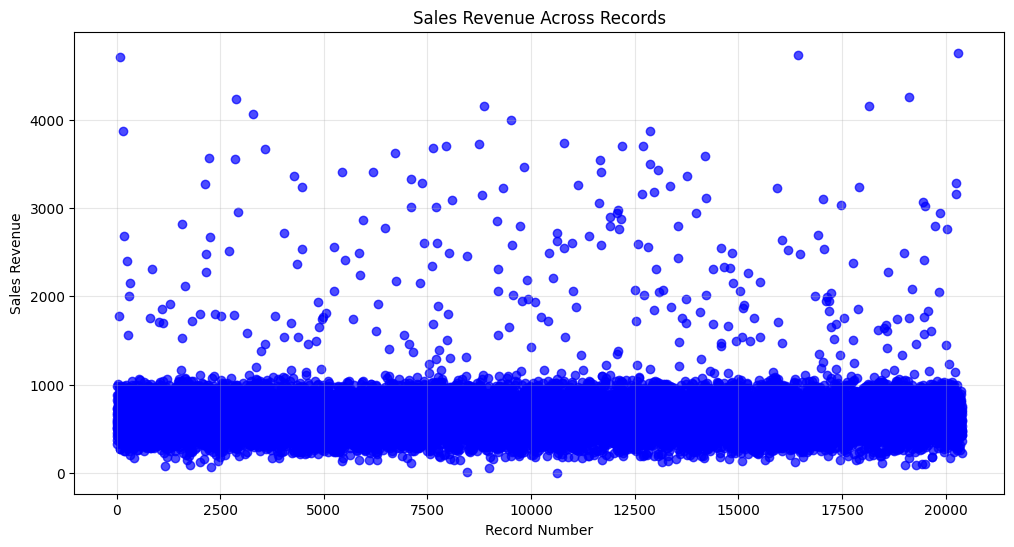

Missing sales values: 491
Missing percentage: 2.50%


In [16]:
df = df.dropna(subset=['Rainfall_Intensity'])

plt.figure(figsize=(12, 6))

plt.scatter(
    df['Counter'],
    df['Sales_Revenue'],
    color='blue',
    alpha=0.7
)

plt.title('Sales Revenue Across Records')
plt.xlabel('Record Number')
plt.ylabel('Sales Revenue')
plt.grid(alpha=0.3)

plt.show()
missing_sales = df['Sales_Revenue'].isna().sum()
missing_percentage = df['Sales_Revenue'].isna().mean() * 100

print(f"Missing sales values: {missing_sales}")
print(f"Missing percentage: {missing_percentage:.2f}%")

In [17]:
corr = round(df.drop(columns=["Counter"]).select_dtypes(include=["number"]).corr(), 2)
corr

,Temperature,Humidity,Is_Weekend,Rainfall_Intensity,Sales_Revenue
Temperature,1.00,-0.01,-0.00,0.01,0.06
Humidity,-0.01,1.00,-0.00,0.01,-0.33
Is_Weekend,-0.00,-0.00,1.00,0.01,0.36
Rainfall_Intensity,0.01,0.01,0.01,1.00,-0.18
Sales_Revenue,0.06,-0.33,0.36,-0.18,1.00


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Remove rows where the target is missing
model_df = df.dropna(subset=['Sales_Revenue']).copy()

features = [
    'Temperature',
    'Humidity',
    'Is_Weekend',
    'Rainfall_Intensity'
]

X = model_df[features]
y = model_df['Sales_Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print(f"MAE: {mean_absolute_error(y_test, predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.2f}")
print(f"R² Score: {r2_score(y_test, predictions):.3f}")

MAE: 109.99
RMSE: 233.33
R² Score: 0.267


In [21]:
import optuna

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

cv = KFold(n_splits=3, shuffle=True, random_state=42)

def objective(trial):
    number_of_layers = trial.suggest_int('number_of_layers', 1, 3)

    hidden_layers = tuple(
        trial.suggest_int(
            f'units_layer_{layer}',
            8,
            128,
            step=8
        )
        for layer in range(number_of_layers)
    )

    model = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=hidden_layers,
            alpha=trial.suggest_float('alpha', 1e-5, 1e-1, log=True),
            learning_rate_init=trial.suggest_float(
                'learning_rate_init',
                1e-4,
                1e-2,
                log=True
            ),
            batch_size=trial.suggest_categorical(
                'batch_size',
                [16, 32, 64]
            ),
            max_iter=2000,
            early_stopping=True,
            random_state=42
        )
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_root_mean_squared_error'
    )

    return -scores.mean()


study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)

print("Best RMSE:", study.best_value)
print("Best parameters:", study.best_params)

[I 2026-10-11 12:41:37,008] A new study created in memory with name: no-name-af489f2d-64be-434a-91fc-87bfa76e8458
[I 2026-10-11 12:41:40,355] Trial 0 finished with value: 233.06376753951375 and parameters: {'number_of_layers': 2, 'units_layer_0': 56, 'units_layer_1': 72, 'alpha': 0.00019874082307598498, 'learning_rate_init': 0.0074142434561149054, 'batch_size': 32}. Best is trial 0 with value: 233.06376753951375.
[I 2026-10-11 12:42:12,363] Trial 1 finished with value: 233.8097300657298 and parameters: {'number_of_layers': 1, 'units_layer_0': 24, 'alpha': 0.0014817001464744054, 'learning_rate_init': 0.00013739446883031045, 'batch_size': 32}. Best is trial 0 with value: 233.06376753951375.
[I 2026-10-11 12:42:19,535] Trial 2 finished with value: 232.21462275142858 and parameters: {'number_of_layers': 3, 'units_layer_0': 64, 'units_layer_1': 88, 'units_layer_2': 32, 'alpha': 0.045760203521384026, 'learning_rate_init': 0.004558121682056111, 'batch_size': 16}. Best is trial 2 with value: 2

Best RMSE: 231.75768201636663
Best parameters: {'number_of_layers': 2, 'units_layer_0': 120, 'units_layer_1': 56, 'alpha': 1.784780689675212e-05, 'learning_rate_init': 0.0009977196961960969, 'batch_size': 16}


In [22]:
best_params = study.best_params

hidden_layers = tuple(
    best_params[f'units_layer_{layer}']
    for layer in range(best_params['number_of_layers'])
)

optimized_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=hidden_layers,
        alpha=best_params['alpha'],
        learning_rate_init=best_params['learning_rate_init'],
        batch_size=best_params['batch_size'],
        max_iter=2000,
        early_stopping=True,
        random_state=42
    )
)

optimized_model.fit(X_train, y_train)

optimized_predictions = optimized_model.predict(X_test)

print(f"MAE: {mean_absolute_error(y_test, optimized_predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, optimized_predictions)):.2f}")
print(f"R² Score: {r2_score(y_test, optimized_predictions):.3f}")

MAE: 106.53
RMSE: 231.41
R² Score: 0.279


In [24]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': optimized_predictions
})

comparison

,Actual,Predicted
4422,723.80,602.045131
3245,977.95,909.233769
4520,724.03,667.671623
6755,757.37,826.866348
212,599.69,629.023618
...,...,...
7143,849.89,852.356762
11500,809.38,734.759888
6114,701.86,622.740577
3238,316.93,395.714683
